In [3]:
# Machine Learning Libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

import warnings
warnings.filterwarnings("ignore")

In [ ]:
# Create binary target variable
import pandas as pd

# Load the dataset
df = pd.read_csv("C:\\Users\\User\\Downloads\\heart+disease\\heart_disease_combined_raw(3).csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()
df_model = df.copy()

df_model['target'] = (df_model['num'] > 0).astype(int)

print("Target distribution:")
print(df_model['target'].value_counts())

print("\nTarget percentage:")
print(df_model['target'].value_counts(normalize=True) * 100)

Dataset loaded successfully!
Shape: (900, 77)
Target distribution:
target
1    496
0    404
Name: count, dtype: int64

Target percentage:
target
1    55.111111
0    44.888889
Name: proportion, dtype: float64


In [7]:
# Clinically relevant features selected for modelling

features = [
    'age',
    'sex',
    'cp',
    'trestbps',
    'chol',
    'fbs',
    'restecg',
    'thalach',
    'exang',
    'oldpeak',
    'slope',
    'ca',
    'thal'
]

X = df_model[features]
y = df_model['target']

print("Selected features:")
print(features)

print("\nFeature matrix shape:", X.shape)
print("Target shape:", y.shape)

Selected features:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']

Feature matrix shape: (900, 13)
Target shape: (900,)


In [8]:
# Split the dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training set: (720, 13)
Testing set: (180, 13)

Training target distribution:
target
1    397
0    323
Name: count, dtype: int64

Testing target distribution:
target
1    99
0    81
Name: count, dtype: int64


In [9]:
# Standardization

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed.")
print("Training data standardized using training-set statistics only.")

Feature scaling completed.
Training data standardized using training-set statistics only.


In [10]:
# Define models

models = {
    "Logistic Regression": Pipeline([
        ('scaler', StandardScaler()),
        ('model', LogisticRegression(max_iter=1000))
    ]),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42
    ),

    "KNN": Pipeline([
        ('scaler', StandardScaler()),
        ('model', KNeighborsClassifier(n_neighbors=5))
    ]),

    "SVM": Pipeline([
        ('scaler', StandardScaler()),
        ('model', SVC(probability=True, random_state=42))
    ]),

    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    )
}

print("Models created:")
for name in models:
    print("-", name)

Models created:
- Logistic Regression
- Decision Tree
- Random Forest
- KNN
- SVM
- Gradient Boosting


In [11]:
# Train and evaluate models

results = []

trained_models = {}

for name, model in models.items():

    # Train
    model.fit(X_train, y_train)

    # Prediction
    y_pred = model.predict(X_test)

    # Probability prediction for ROC-AUC
    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_test)[:, 1]
    else:
        y_prob = model.decision_function(X_test)

    # Metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    auc = roc_auc_score(y_test, y_prob)

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "ROC-AUC": auc
    })

    trained_models[name] = model

results_df = pd.DataFrame(results)

print("Model Evaluation Results:")
display(results_df.round(4))

Model Evaluation Results:


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.8000,0.8058,0.8384,0.8218,0.8677
1,Decision Tree,0.7667,0.7822,0.7980,0.7900,0.7632
2,Random Forest,0.8389,0.8241,0.8990,0.8599,0.9071
3,KNN,0.8333,0.8286,0.8788,0.8529,0.8897
4,SVM,0.8278,0.8148,0.8889,0.8502,0.9108
5,Gradient Boosting,0.8500,0.8333,0.9091,0.8696,0.9171


<Figure size 1200x600 with 0 Axes>

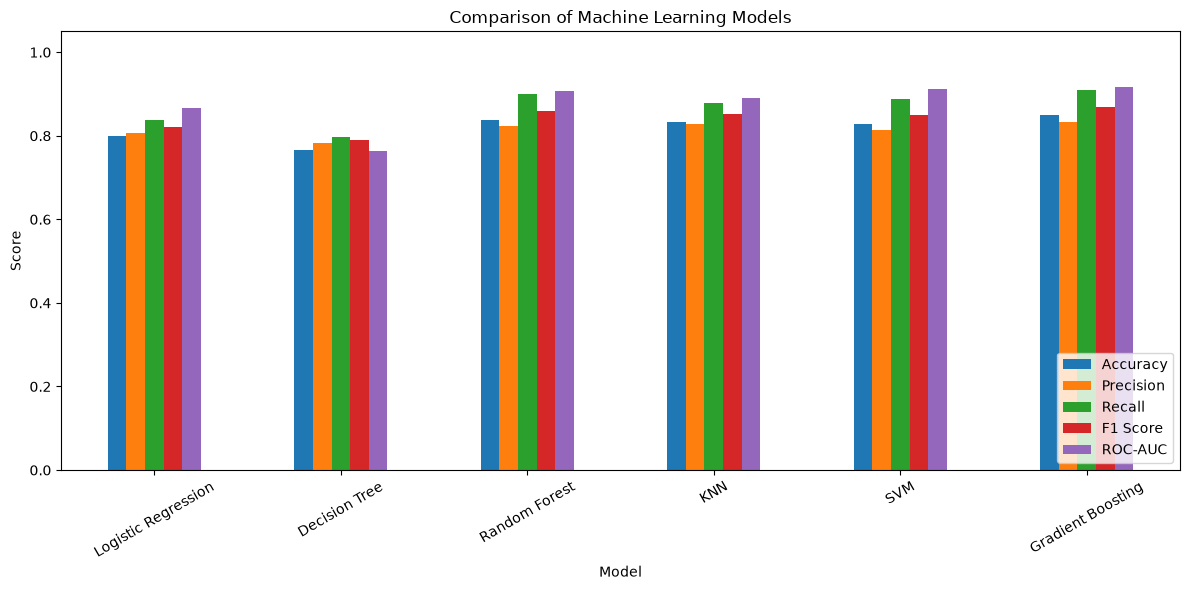

In [12]:
# Model comparison

plt.figure(figsize=(12, 6))

results_plot = results_df.set_index("Model")

results_plot[
    ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]
].plot(kind="bar", figsize=(12, 6))

plt.title("Comparison of Machine Learning Models")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1.05)
plt.xticks(rotation=30)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [13]:
# 5-Fold Stratified Cross Validation

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = []

for name, model in models.items():

    scores = cross_val_score(
        model,
        X,
        y,
        cv=cv,
        scoring="accuracy"
    )

    cv_results.append({
        "Model": name,
        "Mean CV Accuracy": scores.mean(),
        "Standard Deviation": scores.std()
    })

cv_df = pd.DataFrame(cv_results)

print("5-Fold Cross Validation Results:")
display(cv_df.round(4))

5-Fold Cross Validation Results:


,Model,Mean CV Accuracy,Standard Deviation
0,Logistic Regression,0.8011,0.0273
1,Decision Tree,0.7656,0.0379
2,Random Forest,0.8322,0.0197
3,KNN,0.7711,0.0297
4,SVM,0.8000,0.0127
5,Gradient Boosting,0.8211,0.0174


In [16]:
# Hyperparameter Tuning for Random Forest

from sklearn.model_selection import RandomizedSearchCV

rf = RandomForestClassifier(
    random_state=42
)

param_grid = {
    'n_estimators': [100, 150, 200],
    'max_depth': [5, 10, 15, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

random_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_grid,
    n_iter=15,
    cv=3,
    scoring='accuracy',
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_train, y_train)

print("\nBest Parameters:")
print(random_search.best_params_)

print("\nBest Cross-Validation Accuracy:")
print(round(random_search.best_score_, 4))

Fitting 3 folds for each of 15 candidates, totalling 45 fits

Best Parameters:
{'n_estimators': 200, 'min_samples_split': 10, 'min_samples_leaf': 1, 'max_depth': 15}

Best Cross-Validation Accuracy:
0.8264


In [17]:
# Hyperparameter tuning for Random Forest

rf = RandomForestClassifier(
    random_state=42
)

param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 5, 10, 15],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation Accuracy:")
print(round(grid_search.best_score_, 4))

Best Parameters:
{'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 100}

Best Cross-Validation Accuracy:
0.8292


Predictions generated successfully!
Number of test predictions: 180


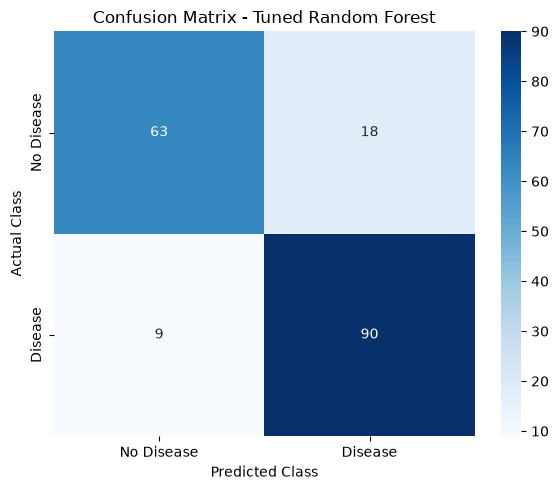

In [19]:
# Confusion Matrix
# Get predictions from the tuned Random Forest

best_rf = random_search.best_estimator_

y_pred_rf = best_rf.predict(X_test)

y_prob_rf = best_rf.predict_proba(X_test)[:, 1]

print("Predictions generated successfully!")
print("Number of test predictions:", len(y_pred_rf))
cm = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Disease', 'Disease'],
    yticklabels=['No Disease', 'Disease']
)

plt.title("Confusion Matrix - Tuned Random Forest")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()

In [20]:
# Feature Importance

importance = best_rf.feature_importances_

feature_importance = pd.DataFrame({
    'Feature': features,
    'Importance': importance
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print("Feature Importance:")
display(feature_importance)

Feature Importance:


,Feature,Importance
2,cp,0.197520
7,thalach,0.132987
4,chol,0.095973
0,age,0.090917
8,exang,0.089656
9,oldpeak,0.081618
10,slope,0.065147
3,trestbps,0.057972
12,thal,0.052090
1,sex,0.050938


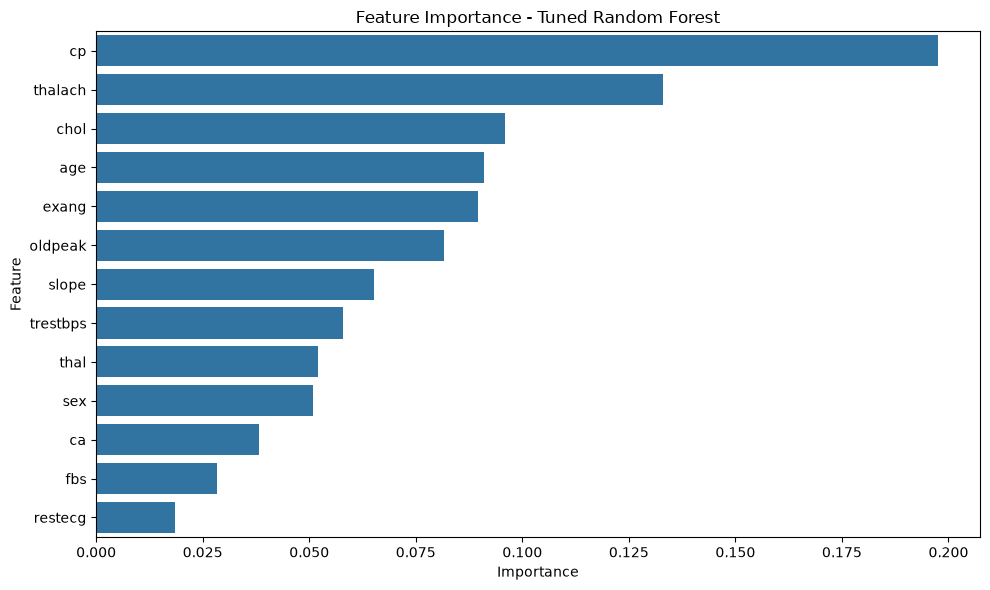

In [21]:
# Plot feature importance

plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x='Importance',
    y='Feature'
)

plt.title("Feature Importance - Tuned Random Forest")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [23]:
# Add tuned Random Forest to comparison
# Calculate metrics for the tuned Random Forest

rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_precision = precision_score(y_test, y_pred_rf, zero_division=0)
rf_recall = recall_score(y_test, y_pred_rf, zero_division=0)
rf_f1 = f1_score(y_test, y_pred_rf, zero_division=0)
rf_auc = roc_auc_score(y_test, y_prob_rf)

print("Tuned Random Forest Performance")
print("--------------------------------")
print("Accuracy :", round(rf_accuracy, 4))
print("Precision:", round(rf_precision, 4))
print("Recall   :", round(rf_recall, 4))
print("F1 Score :", round(rf_f1, 4))
print("ROC-AUC  :", round(rf_auc, 4))
tuned_result = pd.DataFrame([{
    "Model": "Tuned Random Forest",
    "Accuracy": rf_accuracy,
    "Precision": rf_precision,
    "Recall": rf_recall,
    "F1 Score": rf_f1,
    "ROC-AUC": rf_auc
}])

final_comparison = pd.concat(
    [results_df, tuned_result],
    ignore_index=True
)

final_comparison = final_comparison.sort_values(
    by="Accuracy",
    ascending=False
).reset_index(drop=True)

print("Final Model Comparison")
display(final_comparison.round(4))

Tuned Random Forest Performance
--------------------------------
Accuracy : 0.85
Precision: 0.8333
Recall   : 0.9091
F1 Score : 0.8696
ROC-AUC  : 0.9152
Final Model Comparison


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Tuned Random Forest,0.8500,0.8333,0.9091,0.8696,0.9152
1,Gradient Boosting,0.8500,0.8333,0.9091,0.8696,0.9171
2,Random Forest,0.8389,0.8241,0.8990,0.8599,0.9071
3,KNN,0.8333,0.8286,0.8788,0.8529,0.8897
4,SVM,0.8278,0.8148,0.8889,0.8502,0.9108
5,Logistic Regression,0.8000,0.8058,0.8384,0.8218,0.8677
6,Decision Tree,0.7667,0.7822,0.7980,0.7900,0.7632


In [24]:
# Identify the best-performing model

best_model_name = final_comparison.iloc[0]["Model"]

print("Best Performing Model:")
print(best_model_name)

print("\nPerformance:")
display(final_comparison.iloc[[0]].round(4))

Best Performing Model:
Tuned Random Forest

Performance:


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Tuned Random Forest,0.85,0.8333,0.9091,0.8696,0.9152
